In [1]:
import os
import zipfile
import warnings
from pathlib import Path
from io import BytesIO

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

warnings.filterwarnings("ignore")

print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("matplotlib:", matplotlib.__version__)
print("seaborn:", sns.__version__)
print("Random seed:", RANDOM_STATE)

pandas: 2.3.3
numpy: 2.1.3
matplotlib: 3.10.0
seaborn: 0.13.2
Random seed: 42


In [3]:
DATASET_NAME = "Messy_Employee_dataset.csv"

def find_dataset(filename=DATASET_NAME):
    search_roots = [
        Path("/kaggle/input"),
        Path("/kaggle/working"),
        Path.cwd()
    ]

    # Search for an extracted CSV first.
    for root in search_roots:
        if root.exists():
            matches = list(root.rglob(filename))
            if matches:
                return matches[0], None

    # Search ZIP archives if the CSV is not extracted.
    for root in search_roots:
        if root.exists():
            for zip_path in root.rglob("*.zip"):
                try:
                    with zipfile.ZipFile(zip_path) as archive:
                        matches = [
                            name for name in archive.namelist()
                            if Path(name).name == filename
                        ]
                        if matches:
                            return zip_path, matches[0]
                except (zipfile.BadZipFile, OSError):
                    continue

    raise FileNotFoundError(
        f"Could not find {filename}. Add the CSV or its ZIP archive "
        "to /kaggle/input, /kaggle/working, or the notebook directory."
    )

dataset_path, zip_member = find_dataset()

if zip_member is None:
    raw_df = pd.read_csv(dataset_path, encoding="ascii", delimiter=",")
else:
    with zipfile.ZipFile(dataset_path) as archive:
        raw_df = pd.read_csv(
            BytesIO(archive.read(zip_member)),
            encoding="ascii",
            delimiter=","
        )

print("Original shape:", raw_df.shape)
display(raw_df.head())

Original shape: (1020, 12)


,Employee_ID,First_Name,Last_Name,Age,Department_Region,Status,Join_Date,Salary,Email,Phone,Performance_Score,Remote_Work
0,EMP1000,Bob,Davis,25.0,DevOps-California,Active,4/2/2021,59767.65,bob.davis@example.com,-1651623197,Average,True
1,EMP1001,Bob,Brown,NaN,Finance-Texas,Active,7/10/2020,65304.66,bob.brown@example.com,-1898471390,Excellent,True
2,EMP1002,Alice,Jones,NaN,Admin-Nevada,Pending,12/7/2023,88145.90,alice.jones@example.com,-5596363211,Good,True
3,EMP1003,Eva,Davis,25.0,Admin-Nevada,Inactive,11/27/2021,69450.99,eva.davis@example.com,-3476490784,Good,True
4,EMP1004,Frank,Williams,25.0,Cloud Tech-Florida,Active,1/5/2022,109324.61,frank.williams@example.com,-1586734256,Poor,False


In [6]:
print("Dataset information:")
raw_df.info()

print("Missing values in raw data:")
display(raw_df.isnull().sum().to_frame("Missing Values"))

print("Duplicate rows:", raw_df.duplicated().sum())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1020 entries, 0 to 1019
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Employee_ID        1020 non-null   object 
 1   First_Name         1020 non-null   object 
 2   Last_Name          1020 non-null   object 
 3   Age                809 non-null    float64
 4   Department_Region  1020 non-null   object 
 5   Status             1020 non-null   object 
 6   Join_Date          1020 non-null   object 
 7   Salary             996 non-null    float64
 8   Email              1020 non-null   object 
 9   Phone              1020 non-null   int64  
 10  Performance_Score  1020 non-null   object 
 11  Remote_Work        1020 non-null   bool   
dtypes: bool(1), float64(2), int64(1), object(8)
memory usage: 88.8+ KB
Missing values in raw data:


,Missing Values
Employee_ID,0
First_Name,0
Last_Name,0
Age,211
Department_Region,0
Status,0
Join_Date,0
Salary,24
Email,0
Phone,0


Duplicate rows: 0


In [8]:
df = raw_df.copy()

df["Join_Date"] = pd.to_datetime(df["Join_Date"], errors="coerce")
df["Age"] = pd.to_numeric(df["Age"], errors="coerce")
df["Salary"] = pd.to_numeric(df["Salary"], errors="coerce")

# Normalize common text representations if the column is not already boolean.
if df["Remote_Work"].dtype != bool:
    remote_map = {
        "true": True, "false": False,
        "yes": True, "no": False,
        "1": True, "0": False
    }
    df["Remote_Work"] = (
        df["Remote_Work"].astype(str).str.strip().str.lower().map(remote_map)
    )

columns_to_drop = ["Employee_ID", "First_Name", "Last_Name", "Email", "Phone"]
df.drop(columns=columns_to_drop, inplace=True, errors="ignore")

print("Cleaned shape:", df.shape)
print("Missing values after basic cleaning:")
display(df.isnull().sum().to_frame("Missing Values"))
display(df.head())

Cleaned shape: (1020, 7)
Missing values after basic cleaning:


,Missing Values
Age,211
Department_Region,0
Status,0
Join_Date,0
Salary,24
Performance_Score,0
Remote_Work,0


,Age,Department_Region,Status,Join_Date,Salary,Performance_Score,Remote_Work
0,25.0,DevOps-California,Active,2021-04-02,59767.65,Average,True
1,NaN,Finance-Texas,Active,2020-07-10,65304.66,Excellent,True
2,NaN,Admin-Nevada,Pending,2023-12-07,88145.90,Good,True
3,25.0,Admin-Nevada,Inactive,2021-11-27,69450.99,Good,True
4,25.0,Cloud Tech-Florida,Active,2022-01-05,109324.61,Poor,False


In [16]:
print(df.shape)
print(df.columns.tolist())
print(df["Age"].head(10))
print(df["Age"].dtype)
print(df["Age"].isnull().sum())

(1020, 7)
['Age', 'Department_Region', 'Status', 'Join_Date', 'Salary', 'Performance_Score', 'Remote_Work']
0    25.0
1     NaN
2     NaN
3    25.0
4    25.0
5    40.0
6     NaN
7    30.0
8    35.0
9     NaN
Name: Age, dtype: float64
float64
211


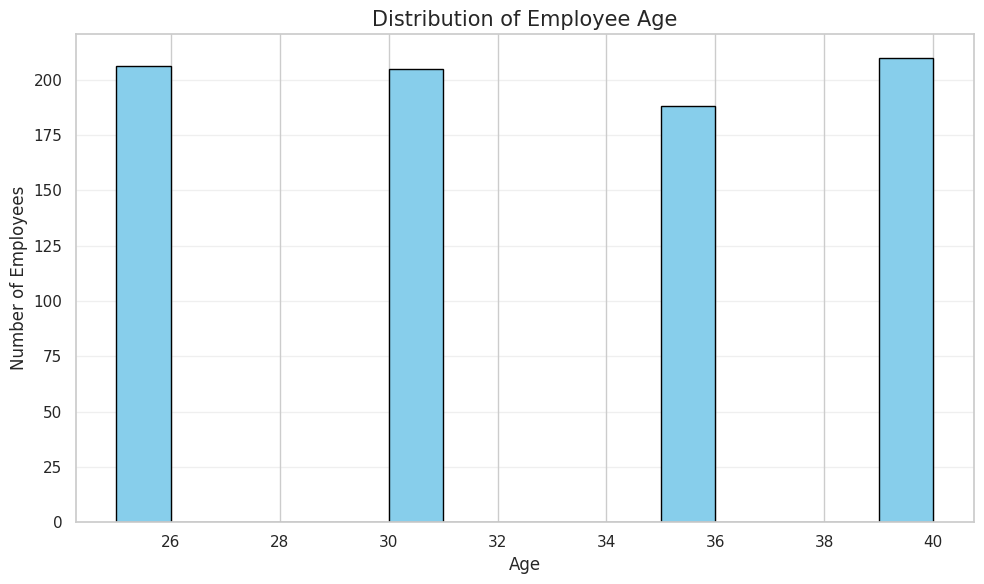

In [25]:
import matplotlib.pyplot as plt
import pandas as pd

# Convert Age into numeric values
df["Age"] = pd.to_numeric(df["Age"], errors="coerce")

# Remove missing values
age = df["Age"].dropna()

# Display histogram
fig, ax = plt.subplots(figsize=(10, 6))

ax.hist(age, bins=15, color="skyblue", edgecolor="black")

ax.set_title("Distribution of Employee Age", fontsize=15)
ax.set_xlabel("Age")
ax.set_ylabel("Number of Employees")

ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

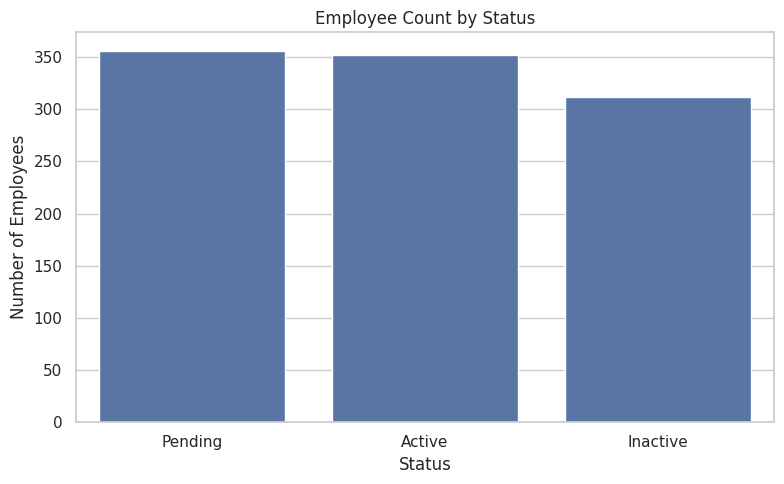

In [26]:
# 2. Employee status count plot
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Status", order=df["Status"].value_counts().index)
plt.title("Employee Count by Status")
plt.xlabel("Status")
plt.ylabel("Number of Employees")
plt.tight_layout()
plt.show()

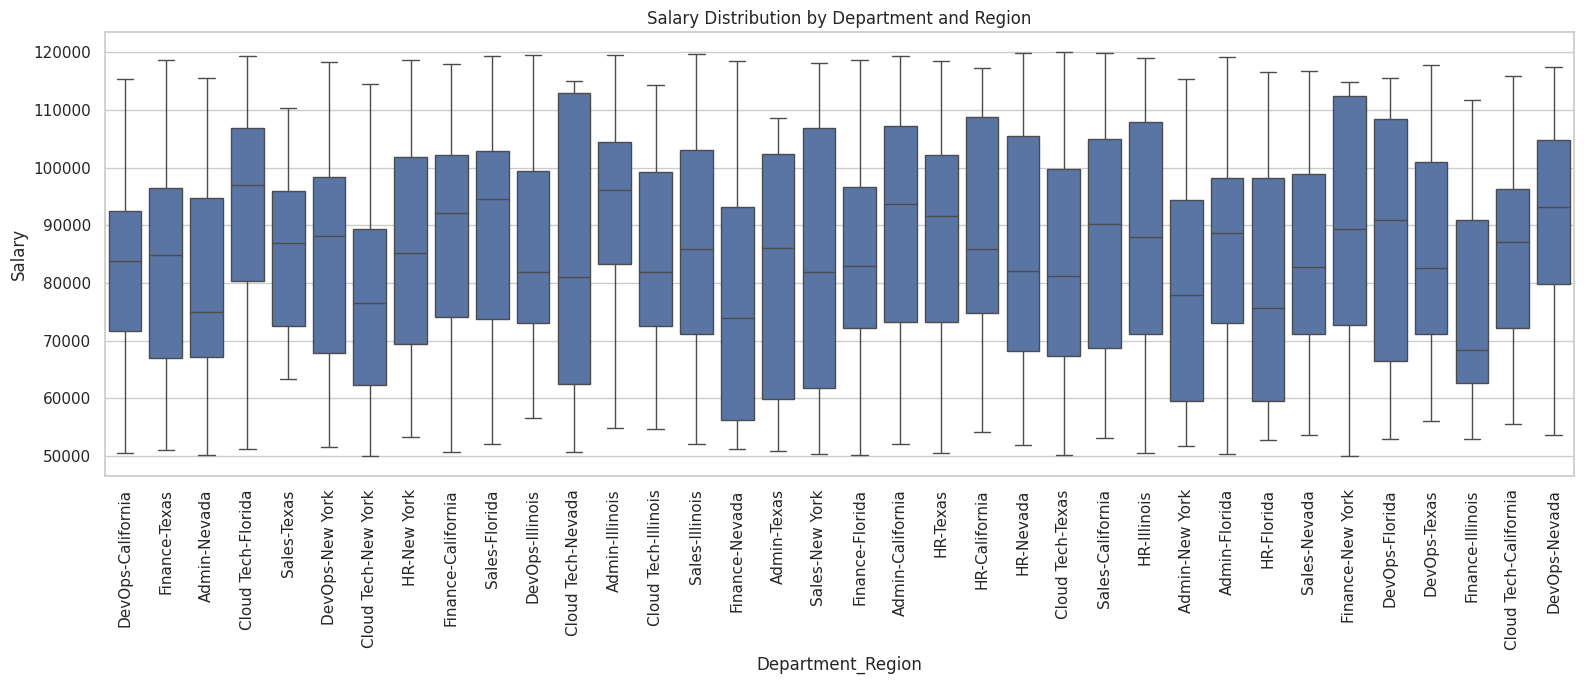

Unique Department_Region labels: 36


In [22]:
# 3. Salary box plot by Department_Region
plt.figure(figsize=(16, 7))
sns.boxplot(data=df, x="Department_Region", y="Salary")
plt.title("Salary Distribution by Department and Region")
plt.xlabel("Department_Region")
plt.ylabel("Salary")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

print("Unique Department_Region labels:", df["Department_Region"].nunique())

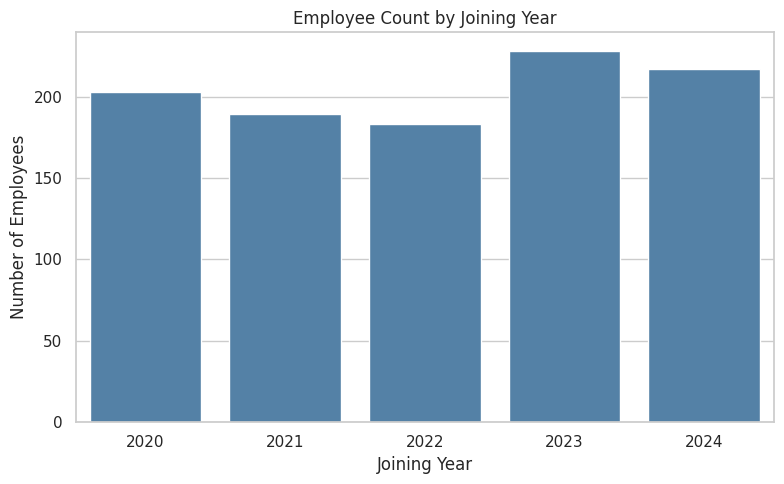

In [23]:
# 4. Employee join-year count plot
join_year = df["Join_Date"].dt.year
plt.figure(figsize=(8, 5))
sns.countplot(x=join_year.dropna().astype(int), color="steelblue")
plt.title("Employee Count by Joining Year")
plt.xlabel("Joining Year")
plt.ylabel("Number of Employees")
plt.tight_layout()
plt.show()

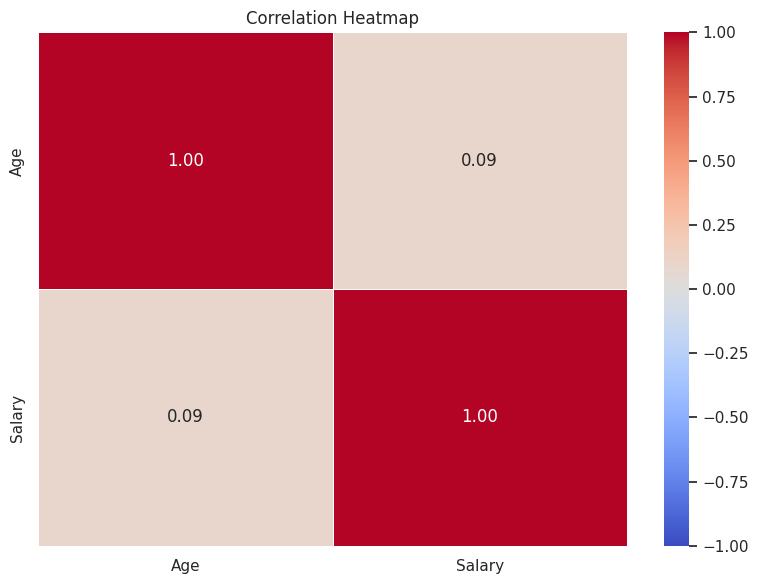

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Select numeric columns
numeric_df = df.select_dtypes(include=np.number)

# Generate correlation heatmap if at least 2 numeric columns exist
if numeric_df.shape[1] >= 2:

    plt.figure(figsize=(8, 6))

    sns.heatmap(
        numeric_df.corr(),
        annot=True,
        cmap="coolwarm",
        fmt=".2f",
        linewidths=0.5,
        vmin=-1,
        vmax=1
    )

    plt.title("Correlation Heatmap")
    plt.tight_layout()
    plt.show()

else:
    print("At least 2 numeric columns are required for correlation analysis.")

In [28]:
model_df = df.copy()

# Create a numeric tenure feature using the current date.
analysis_date = pd.Timestamp.today().normalize()
model_df["Days_Since_Join"] = (
    analysis_date - model_df["Join_Date"]
).dt.days

# Convert boolean feature to numeric.
model_df["Remote_Work"] = model_df["Remote_Work"].astype("Int64")

# Drop Join_Date after extracting the numeric date feature.
model_df.drop(columns=["Join_Date"], inplace=True)

# Drop rows with missing values for this model.
rows_before_dropna = len(model_df)
model_df = model_df.dropna().copy()
rows_after_dropna = len(model_df)

print("Rows before dropping missing values:", rows_before_dropna)
print("Rows after dropping missing values:", rows_after_dropna)
print("Rows removed:", rows_before_dropna - rows_after_dropna)
print("Percentage removed:", round(
    (rows_before_dropna - rows_after_dropna) / rows_before_dropna * 100, 2
), "%")

if model_df.empty:
    raise ValueError("No rows remain after removing missing values.")

Rows before dropping missing values: 1020
Rows after dropping missing values: 787
Rows removed: 233
Percentage removed: 22.84 %


In [29]:
target_column = "Performance_Score"

if target_column not in model_df.columns:
    raise KeyError(f"Target column '{target_column}' was not found.")

# Separate target from predictors before encoding.
X = model_df.drop(columns=[target_column]).copy()
y_text = model_df[target_column].astype(str)

# One-hot encode Department_Region and Status.
categorical_columns = X.select_dtypes(include=["object", "category"]).columns.tolist()
X = pd.get_dummies(
    X,
    columns=categorical_columns,
    drop_first=False,
    dtype=int
)

# Ensure every model input is numeric.
X = X.apply(pd.to_numeric, errors="coerce")
X = X.replace([np.inf, -np.inf], np.nan)

# Defensive check: remove any rows that became missing during conversion.
valid_rows = X.notna().all(axis=1) & y_text.notna()
X = X.loc[valid_rows].copy()
y_text = y_text.loc[valid_rows].copy()

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_text)

print("Target classes:", list(label_encoder.classes_))
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("All features numeric:", all(
    pd.api.types.is_numeric_dtype(dtype) for dtype in X.dtypes
))

Target classes: ['Average', 'Excellent', 'Good', 'Poor']
Feature matrix shape: (787, 43)
Target shape: (787,)
All features numeric: True


In [30]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)
print("Training target distribution:")
display(pd.Series(
    label_encoder.inverse_transform(y_train)
).value_counts().to_frame("Count"))

Training feature shape: (550, 43)
Testing feature shape: (237, 43)
Training target distribution:


,Count
Average,152
Good,142
Excellent,139
Poor,117


In [31]:
random_forest = RandomForestClassifier(
    n_estimators=100,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

random_forest.fit(X_train, y_train)
y_pred = random_forest.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print(f"Random Forest Accuracy: {accuracy:.4f}")
print("\\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    zero_division=0
))

Random Forest Accuracy: 0.2911
\nClassification Report:
              precision    recall  f1-score   support

     Average       0.27      0.24      0.25        66
   Excellent       0.30      0.32      0.31        60
        Good       0.28      0.31      0.29        61
        Poor       0.33      0.30      0.32        50

    accuracy                           0.29       237
   macro avg       0.29      0.29      0.29       237
weighted avg       0.29      0.29      0.29       237



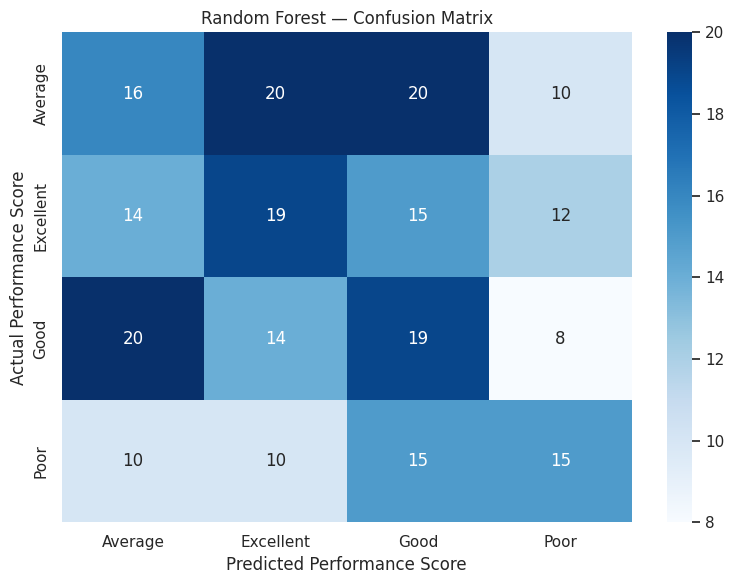

In [32]:
# Confusion matrix heatmap
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(len(label_encoder.classes_))
)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)
plt.title("Random Forest — Confusion Matrix")
plt.xlabel("Predicted Performance Score")
plt.ylabel("Actual Performance Score")
plt.tight_layout()
plt.show()